# Семинар по теме «Метрики задач регрессии и классификаций. Кросс-валидация и подбор гиперпараметров»

Из этого семинара ты узнаешь:
* на что влияет функция потерь при обучении регрессионных моделей;
* как выбросы в обучающей разметке влияют на модели с разными функциями потерь;
* как работать с Confusion Matrix и метриками классификации;
* как подбирать параметры для метрик, основываясь на их логике и бизнес-предпочтениях.

Во второй части семинара - познакомишься с методами кросс-валидации и подбора гиперпараметров.  

#### Подготовка

In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Импорт библиотек
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

## Регрессия и выбор Loss-функции

Ты уже знаешь, что задача регрессии — предсказание непрерывной числовой величины на основе входных признаков.

В рамках этого блока мы поработаем с датасетом Medical Cost Personal Datasets, который расположен на платформе Kaggle.

Целевая переменная датасета `charges` — индивидуальные медицинские расходы (в долларах), оплаченные страховой компанией.

Подробнее о признаках можно прочитать [здесь](https://www.kaggle.com/datasets/mirichoi0218/insurance).

In [ ]:
!gdown 1B2uUprgzLZHxaEf6wqFwgVWTgC1P_4hv

Downloading...
From: https://drive.google.com/uc?id=1B2uUprgzLZHxaEf6wqFwgVWTgC1P_4hv
To: /content/insurance.csv
100% 55.6k/55.6k [00:00<00:00, 76.2MB/s]


In [ ]:
df = pd.read_csv('/content/insurance.csv')
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


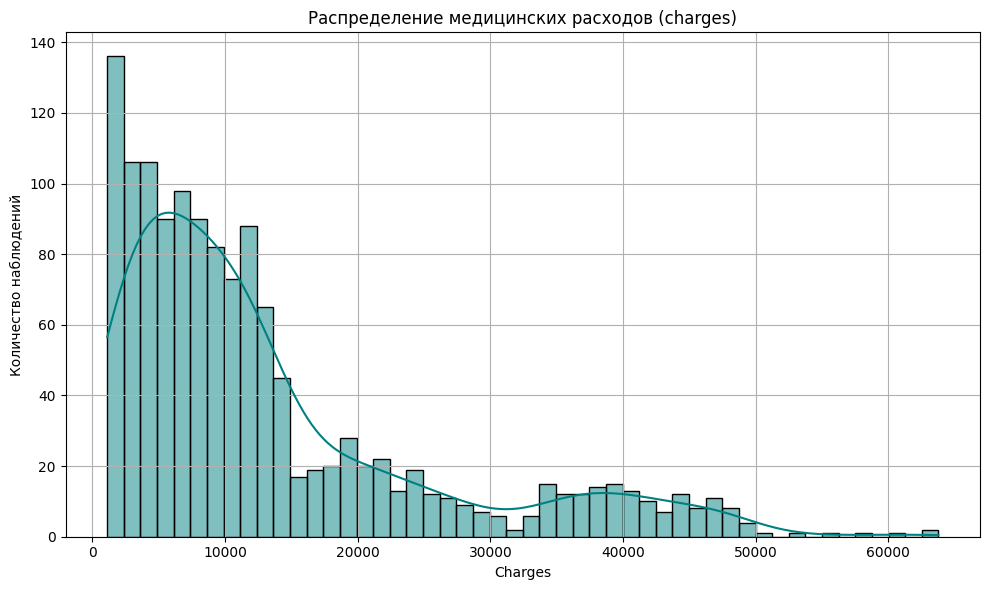

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(df["charges"], bins=50, kde=True, color="teal")
plt.title("Распределение медицинских расходов (charges)")
plt.xlabel("Charges")
plt.ylabel("Количество наблюдений")
plt.grid(True)
plt.tight_layout()
plt.show()


На графике видно, что распределение `charges` скошено вправо: у большинства пациентов расходы сравнительно небольшие, но у некоторых расходы довольно высокие (это выбросы относительно большей части выборки).

Нам важно знать о таких нюансах, потому что при обучении модели регрессии обычно оптимизируют функцию потерь, например MSE (Mean Squared Error) или MAE (Mean Absolute Error). Они по-разному реагируют на выбросы.
* MSE сильно штрафует большие ошибки: квадратичное возведение ошибки увеличивает влияние выбросов на обучение модели.
* MAE же, напротив, более устойчива к выбросам: линейная функция ошибки не даёт большой вес редким экстремальным значениям.

Функция потерь формирует поведение модели при оптимизации, поэтому желательно подобрать её так, чтобы она помогала, а не мешала решать задачу. Например:
* Если для задачи важна точность в среднем — можно использовать MSE. Тогда модель будет стремиться минимизировать крупные ошибки.
* Если в данных много выбросов или шумных наблюдений, которые могут дать искажённый результат, стоит взять MAE.

Ключевые выводы:
* Контекст задачи и погружение в структуру данных важны для подбора метрик и функций потерь.
* Глубокое понимание распределения целевой переменной и влияния функций потерь — ключ к построению моделей, которые делают правильные прогнозы там, где это важно.



In [ ]:
# Отделяем целевую переменную
X, y = df.drop("charges", axis=1), df["charges"]

# Категориальные и числовые признаки
categorical_features = ["sex", "smoker", "region"]
numerical_features = ["age", "bmi", "children"]

# Создаём трансформер для категориальных признаков
preprocessor = ColumnTransformer(transformers=[
    ("cat", OneHotEncoder(drop="first"), categorical_features)
], remainder="passthrough")  # Остальные признаки оставляем как есть

# Делим на Train/Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Пример пайплайна с моделью
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Обучение модели
model.fit(X_train, y_train)

# Предсказания (опционально)
y_pred = model.predict(X_test)

### Задача 1

Сравним, как меняется поведение модели в зависимости от выбранной функции потерь.

1. Обучи две модели [GradientBoostingRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingRegressor.html) на одних и тех же данных `X_train`/` y_train` (см. пример обучения выше), используя разные функции потерь:

 * `squared_error` (MSE) — штрафует большие ошибки сильнее, что делает модель чувствительной к выбросам.
 * `absolute_error` (MAE) — штрафует ошибки линейно, что снижает влияние выбросов.

> **Примечание.** `GradientBoostingRegressor` является моделью машинного обучения из библиотеки `sklearn`, которая строит ансамбль решающих деревьев последовательно так, чтобы каждое дерево исправляло ошибки предыдущих. Будем рассматривать эту модель как чёрный ящик, но в рамках этого курса ты познакомишься с ней ближе.


2. Для каждой модели сделай предсказания на тестовой выборке.
3. Вычисли и сравни ключевые метрики качества (MSE, MAE, RMSE, MAPE, R²).
4. Чтобы визуально проанализировать ошибки модели, для каждой модели построй [Residual Plot](https://seaborn.pydata.org/generated/seaborn.residplot.html) — график остатков по оси $Y$ (реальное значение — предсказанное) против предсказанных значений по оси $X$.



In [ ]:
# Функция для вывода метрик
def print_metrics(y_true, y_pred, model_name):
    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    r2 = r2_score(y_true, y_pred)
    print(f"Метрики для {model_name}:")
    print(f"  MSE:  {mse:.2f}")
    print(f"  MAE:  {mae:.2f}")
    print(f"  RMSE: {rmse:.2f}")
    print(f"  MAPE: {mape:.2f}%")
    print(f"  R2:   {r2:.3f}\n")

In [ ]:
# Напиши код здесь

**Вопросы**
1. Как меняется распределение ошибок (остатков) для моделей с разными Loss-функциями?
2. Какая модель лучше справляется с выбросами и почему?

### Решение

Метрики для Gradient Boosting (MSE):
  MSE:  18792571.23
  MAE:  2454.47
  RMSE: 4335.04
  MAPE: 30.01%
  R2:   0.879

Метрики для Gradient Boosting (MAE):
  MSE:  25602676.30
  MAE:  1957.33
  RMSE: 5059.91
  MAPE: 8.98%
  R2:   0.835



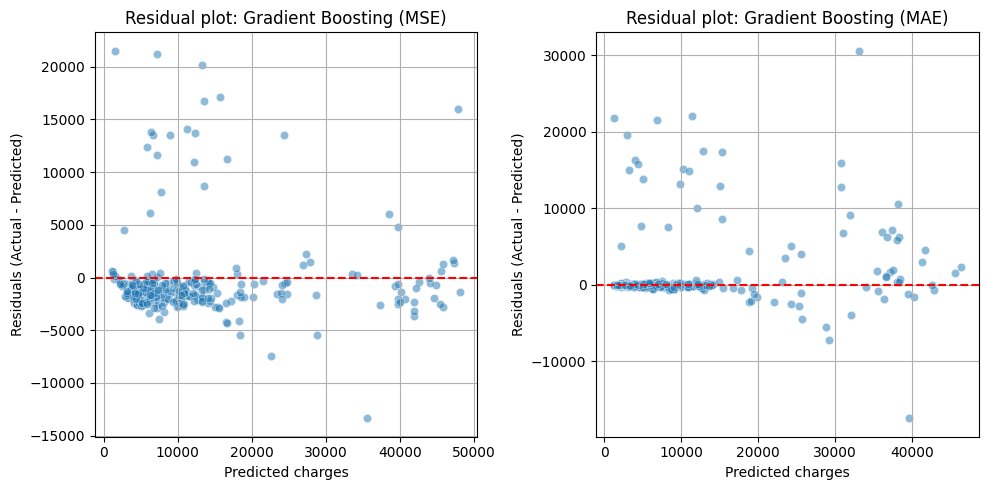

In [ ]:
# Градиентный бустинг с loss='squared_error' (MSE)
gbr_mse_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", GradientBoostingRegressor(loss='squared_error', random_state=42))
])
gbr_mse_pipeline.fit(X_train, y_train)
y_pred_gbr_mse = gbr_mse_pipeline.predict(X_test)

# Градиентный бустинг с loss='absolute_error' (MAE)
gbr_mae_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", GradientBoostingRegressor(loss='absolute_error', random_state=42))
])
gbr_mae_pipeline.fit(X_train, y_train)
y_pred_gbr_mae = gbr_mae_pipeline.predict(X_test)


print_metrics(y_test, y_pred_gbr_mse, "Gradient Boosting (MSE)")
print_metrics(y_test, y_pred_gbr_mae, "Gradient Boosting (MAE)")

# Визуализация остатков
plt.figure(figsize=(15, 5))
for i, (y_pred, title) in enumerate(zip(
    [y_pred_gbr_mse, y_pred_gbr_mae],
    ["Gradient Boosting (MSE)", "Gradient Boosting (MAE)"]
)):
    residuals = y_test - y_pred
    plt.subplot(1, 3, i+1)
    sns.scatterplot(x=y_pred, y=residuals, alpha=0.5)
    plt.axhline(0, color='red', linestyle='--')
    plt.title(f"Residual plot: {title}")
    plt.xlabel("Predicted charges")
    plt.ylabel("Residuals (Actual - Predicted)")
    plt.grid(True)

plt.tight_layout()
plt.show()


**Ответы**

Gradient Boosting (MSE):
* Низкая MSE и высокий R² (0,879). В среднем модель хорошо подстраивается под данные.
* Однако MAE = 2454, MAPE = 30%. Это значит, что модель допускает относительно большие ошибки на отдельных точках, особенно в малых значениях.
* Такое поведение характерно для MSE: модель фокусируется на выбросах и старается минимизировать большие ошибки, «жертвуя» точностью на типичных значениях.

Gradient Boosting (MAE):
* Выше MSE и ниже R² (0,835). Модель хуже объясняет дисперсию целевой переменной.
* Однако MAE = 1957, MAPE = 9%. В среднем модель точнее на типичных значениях (особенно в малых и средних значениях `charges`).
* Это ожидаемо: MAE учитывает большие ошибки линейно, поэтому они слабее влияют на обучение, чем при MSE.

Итоги:
* MSE-модель лучше по R² и RMSE, но хуже по MAE и MAPE. Это значит, что она ориентирована на глобальное приближение и очень чувствительна к выбросам.
* MAE-модель точнее в предсказаниях для большинства клиентов, но хуже описывает редкие, дорогие случаи.

Стоит отметить, что при работе с такими данными нормой считается логарифмирование (применение функции натурального логарифма) целевой переменной. Это позволяет:
* Выравнять сильно смещённое распределение.
* Снизить влияние выбросов и стабилизировать обучение модели.
* Улучшить линейную связь между признаками и таргетом — она станет больше похожа на прямую линию.






### Задача 2. Выбросы в обучающей выборке

Проверим, как ошибки в обучающей разметке влияют на прогнозы моделей с разными функциями потерь. Искусственно увеличим несколько ответов в обучающей выборке, заново обучим модели и оценим их на исходном тесте. При обучении модель подбирает прогнозы, стараясь уменьшить выбранный лосс; устройство бустинга для этого опыта знать не требуется.

1. Создай копию `y_train`: `y_train_outliers`. При `np.random.seed(42)` выбери 10 случайных объектов без повторений и умножь их целевые значения на случайные коэффициенты от 5 до 15. Это меньше 1% обучающей выборки. Признаки и исходный `y_train` оставь без изменений.
2. Создай и обучи две новые модели `GradientBoostingRegressor` на `X_train` и `y_train_outliers`: с `loss='squared_error'` и `loss='absolute_error'`. Используй те же параметры, что в задаче 1, включая `random_state=42`. Для каждого нового пайплайна создай отдельную копию препроцессора с помощью `clone(preprocessor)`.
3. На исходном тесте `X_test` / `y_test` сравни четыре варианта: MSE-модель и MAE-модель, каждая обученная на исходной выборке и на выборке с искусственными выбросами. Используй функцию `print_metrics` из задачи 1. Для каждой модели сравни метрики до и после изменения обучающей разметки.
4. Для каждого лосса посчитай среднее абсолютное изменение тестового прогноза после переобучения: `np.mean(np.abs(y_pred_dirty - y_pred_original))`.

Тестовую выборку не меняем: все четыре модели оцениваются на одних и тех же объектах и ответах. Под «исходным тестом» здесь понимается разметка до искусственного добавления выбросов.

In [ ]:
# Напиши код здесь

**Вопросы**
1. Как изменились метрики каждой модели на исходном тесте после добавления выбросов в обучение?
2. У какой модели сильнее изменились прогнозы? Объясни результат через различие штрафов MSE и MAE.
3. Почему для сравнения важно сохранить тестовую выборку неизменной? Означает ли результат этого опыта, что MAE всегда лучше MSE?

### Решение задачи 2

In [ ]:
# Копируем ответы и добавляем выбросы только в обучающую разметку
y_train_outliers = y_train.copy()
np.random.seed(42)
train_outlier_idx = np.random.choice(y_train_outliers.index, size=10, replace=False)
y_train_outliers.loc[train_outlier_idx] *= np.random.uniform(5, 15, size=10)

print(pd.DataFrame({
    "было": y_train.loc[train_outlier_idx],
    "стало": y_train_outliers.loc[train_outlier_idx],
}).round(0))

from sklearn.base import clone

# У каждого нового пайплайна свой препроцессор
gbr_mse_dirty = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("regressor", GradientBoostingRegressor(loss='squared_error', random_state=42))
])
gbr_mse_dirty.fit(X_train, y_train_outliers)

gbr_mae_dirty = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("regressor", GradientBoostingRegressor(loss='absolute_error', random_state=42))
])
gbr_mae_dirty.fit(X_train, y_train_outliers)

y_pred_gbr_mse_dirty = gbr_mse_dirty.predict(X_test)
y_pred_gbr_mae_dirty = gbr_mae_dirty.predict(X_test)

# Все четыре варианта оцениваем на исходном тесте
print_metrics(y_test, y_pred_gbr_mse, "MSE: исходный train")
print_metrics(y_test, y_pred_gbr_mse_dirty, "MSE: train с выбросами")
print_metrics(y_test, y_pred_gbr_mae, "MAE: исходный train")
print_metrics(y_test, y_pred_gbr_mae_dirty, "MAE: train с выбросами")

print("Среднее абсолютное изменение прогноза, доллары:")
print("MSE-модель:", round(np.mean(np.abs(y_pred_gbr_mse_dirty - y_pred_gbr_mse))))
print("MAE-модель:", round(np.mean(np.abs(y_pred_gbr_mae_dirty - y_pred_gbr_mae))))

         было     стало
1049  39728.0  494190.0
257    5401.0   28816.0
1022  42211.0  451613.0
1071  13974.0  176422.0
17     2395.0   32976.0
740    8604.0   72457.0
1006   4438.0   58641.0
815    1878.0   11467.0
704    8931.0  120251.0
596    7640.0   47942.0
Метрики для MSE: исходный train:
  MSE:  18792571.23
  MAE:  2454.47
  RMSE: 4335.04
  MAPE: 30.01%
  R2:   0.879

Метрики для MSE: train с выбросами:
  MSE:  52997192.63
  MAE:  3515.19
  RMSE: 7279.92
  MAPE: 38.29%
  R2:   0.659

Метрики для MAE: исходный train:
  MSE:  25602676.30
  MAE:  1957.33
  RMSE: 5059.91
  MAPE: 8.98%
  R2:   0.835

Метрики для MAE: train с выбросами:
  MSE:  26548720.72
  MAE:  1938.40
  RMSE: 5152.55
  MAPE: 9.31%
  R2:   0.829

Среднее абсолютное изменение прогноза, доллары:
MSE-модель: 1925
MAE-модель: 395


**Ответы**

В этом эксперименте десять изменённых ответов из 1070 заметно ухудшили качество MSE-модели на исходном тесте: RMSE вырос примерно с 4335 до 7280 долларов, MAE с 2454 до 3515, R² снизился с 0,88 до 0,66. У MAE-модели изменения меньше: RMSE вырос с 5060 до 5153, R² снизился с 0,84 до 0,83, а MAE немного уменьшилась, с 1957 до 1938.

Изменились и сами прогнозы: среднее абсолютное изменение составляет примерно 1925 долларов для MSE-модели и 395 долларов для MAE-модели.

MSE квадратично штрафует большие ошибки, поэтому искусственно увеличенные ответы могут сильно влиять на обучение. В MAE штраф растёт линейно. В данном опыте модель с MAE оказалась менее чувствительна к этим изменениям разметки. Связь MAE с медианой, разобранная для константного прогноза, помогает понять различие лоссов, но здесь модель использует признаки и не предсказывает одну общую медиану.

Неизменный тест позволяет сравнить последствия изменения обучающей разметки на общей основе. Результат относится к этому набору данных, моделям и выбранным выбросам: он не означает, что MAE всегда лучше MSE. Небольшое улучшение MAE на одном разбиении также не доказывает пользу испорченной разметки.

## Конфликт метрик в задаче классификации

Переходим к задачам классификации.

Напомним, что ключевое отличие между регрессией и классификацией в целевой переменной, которую необходимо предсказать:
* задача классификации — предсказание категории/класса из ограниченного множества;
* задача регрессии — предсказание непрерывного численного значения.


В лонгриде и лекции мы подробно обсуждали метрики классификации, их различия, особенности и недостатки. Рассмотрим эти метрики, используя датасет [Сredit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud/data) с Kaggle. В датасете отсутствует информация об исходных признаках и контексте данных в целом. Вот что об этом пишут авторы:

> «К сожалению, из-за вопросов конфиденциальности мы не можем предоставить исходные признаки и дополнительную информацию о данных. Признаки V1, V2, … V28 — это главные компоненты, полученные с помощью PCA; единственные признаки, которые не были преобразованы с помощью PCA — это `Time` и `Amount`».

Сейчас нам неважно, какие именно признаки в нём содержатся, мы даже пропустим нормализацию и будем рассматривать датасет как набор банковских данных для классификации, в котором:

* класс `0` означает отсутствие мошенничества;
* класс `1` означает наличие мошенничества.

In [ ]:
!gdown 12JMj56fmT_hS60V9B2uNOvYJs8zaS5ZC

Downloading...
From (original): https://drive.google.com/uc?id=12JMj56fmT_hS60V9B2uNOvYJs8zaS5ZC
From (redirected): https://drive.google.com/uc?id=12JMj56fmT_hS60V9B2uNOvYJs8zaS5ZC&confirm=t&uuid=8bbd349d-f2ba-4593-9273-9524fc4b84e6
To: /content/creditcard.csv
100% 151M/151M [00:02<00:00, 64.0MB/s]


In [ ]:
data = pd.read_csv('creditcard.csv')
data.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [ ]:
# Разбиваем данные на признаки и целевую переменную
X, y = data.drop('Class', axis=1), data['Class']

Визуализируем распределение классов в датасете.

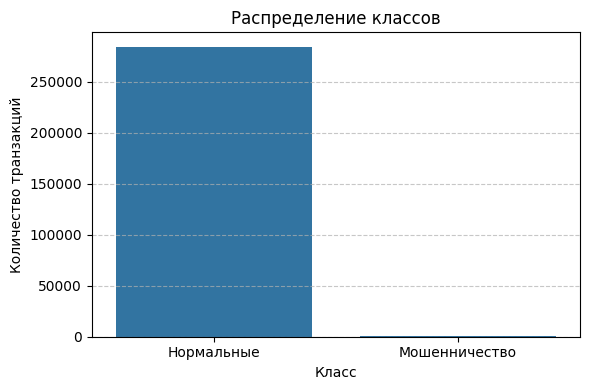

Доля мошенничеств: 0.1727%


In [ ]:
# Подсчёт распределения
class_counts = data['Class'].value_counts().sort_index()

# Визуализация
plt.figure(figsize=(6, 4))
sns.barplot(x = class_counts.index, y = class_counts.values)
plt.title('Распределение классов')
plt.xlabel('Класс')
plt.ylabel('Количество транзакций')
plt.xticks([0, 1], ['Нормальные', 'Мошенничество'])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Также выведем долю положительных классов
fraud_ratio = class_counts[1] / class_counts.sum()
print(f"Доля мошенничеств: {fraud_ratio:.4%}")

Обрати внимание, что классы совсем не сбалансированы — это нормально для таких данных. Статистически мошенников значительно меньше, особенно если рассматривать всю выборку.

In [ ]:
# ВНИМАНИЕ: из-за размера датасета ячейка будет отрабатывать чуть больше чем 1 минуту!

# Разобьём данные на тренировочную и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, stratify = y, random_state = 42) # Обрати внимание, что split мы сделали с учётом баланса классов (stratify)

# Обучим модель логистической регрессии
model = LogisticRegression(max_iter=1000, random_state = 42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

### Задача 3

У нас есть предсказания модели `y_pred` и истинные метки объектов тестовой выборки `y_test`.

1. Построй `confusion matrix` с использованием [sklearn.metrics.confusion_matrix](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html).
2. Визуализируй `confusion matrix` с помощью `seaborn.heatmap`.
3. Подпиши оси и добавь заголовок, чтобы улучшить читаемость.

In [ ]:
# Напиши код здесь

### Решение

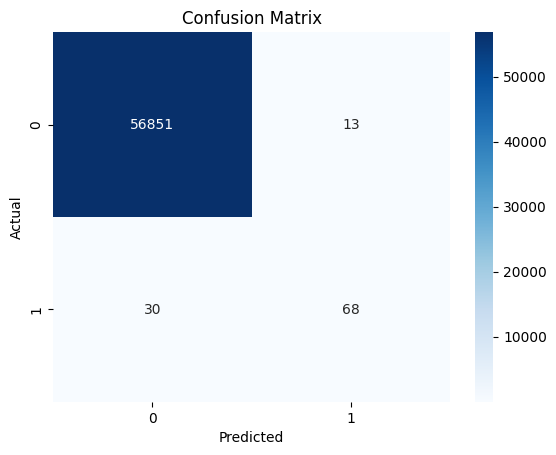

In [ ]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

### Задача 4

Теперь твоя задача — вручную рассчитать ключевые метрики качества модели, используя только значения из матрицы ошибок.

1. Извлеки значения TP, TN, FP, FN из матрицы ошибок.

2. Вручную по формулам рассчитай следующие метрики:
 * Accuracy,
 * Precision,
 * Recall,
 * F1-score.
3. Выведи значения в удобном для тебя формате.

In [ ]:
# Напиши код здесь

### Решение

In [ ]:
# Извлекаем значения из Confusion Matrix
TN, FP, FN, TP = cm.ravel()

# Accuracy
accuracy = (TP + TN) / (TP + TN + FP + FN)

# Precision
precision = TP / (TP + FP) if (TP + FP) != 0 else 0

# Recall
recall = TP / (TP + FN) if (TP + FN) != 0 else 0

# F1-score
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) != 0 else 0

# Выводим
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")


Accuracy:  0.9992
Precision: 0.8395
Recall:    0.6939
F1-score:  0.7598


**Вопрос.** Почему высокая `accuracy` здесь обманчива?

**Ответ.** `Accuracy` не подходит для оценки модели на несбалансированных данных — значение метрики может быть высоким даже при плохом качестве предсказания для миноритарного класса. Условно у нас настолько мало примеров положительного класса, что даже если все примеры будут предсказаны как отрицательные, `accuracy` всё равно будет высокой.

In [ ]:
# Какой будет Accuracy, если все наши предсказания будут отрицательными?
accuracy_score(y_test, np.zeros_like(y_test))

0.9982795547909132

 > **Примечание.**  Значение `accuracy` для модели и для отрицательного массива практически не отличаются.

### Задача 5

Для следующего примера `accuracy` — не сильно репрезентативная метрика. Можно использовать `precision`, `recall` или их комбинацию — `F-beta score`. Но как выбрать подходящую `beta` и на что она вообще влияет?

Рассмотрим на примере.

1. Задай фиксированные значения `precision` и `recall`, которые были получены на модели выше.
2. Построй график `F-beta score` в зависимости от `β` для каждого `β` из `np.linspace(0.1, 3, 100)`. Можно использовать функцию [sklearn.metrics.fbeta_score](hhttps://scikit-learn.org/stable/modules/generated/sklearn.metrics.fbeta_score.html) или считать значения вручную.
3. Оставь подписи на графике и отметь значения для `β = 0.5, 1, 2`.

In [ ]:
# Напиши код здесь

### Решение

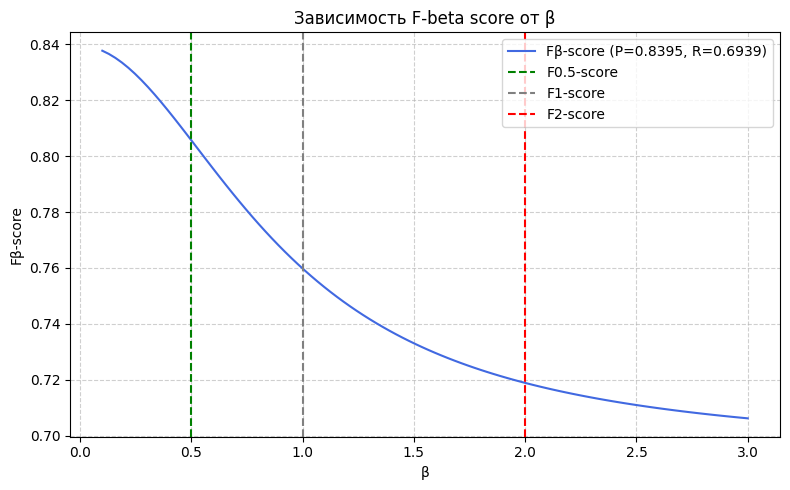

In [ ]:
# Выше мы получили следующие значения Precision и Recall
precision = 0.8395
recall = 0.6939

# Диапазон значений β
betas = np.linspace(0.1, 3, 100)

# Расчёт Fβ для каждого значения β из linspace
f_beta_scores = [
    (1 + beta**2) * precision * recall / (beta**2 * precision + recall)
    for beta in betas
]

# Визуализация
plt.figure(figsize=(8, 5))
plt.plot(betas, f_beta_scores, label=f'Fβ-score (P={precision}, R={recall})', color='royalblue')
plt.axvline(x=0.5, linestyle='--', color='green', label='F0.5-score')
plt.axvline(x=1, linestyle='--', color='gray', label='F1-score')
plt.axvline(x=2, linestyle='--', color='red', label='F2-score')
plt.xlabel('β')
plt.ylabel('Fβ-score')
plt.title('Зависимость F-beta score от β')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


**Вопросы.** Как можно интерпретировать этот график? Можно ли по нему определить оптимальное значение `beta` для задачи?

**Ответ.** В этом вопросе есть небольшой подвох.

Самого по себе значения метрики, например `F1 = 0.65`, недостаточно для оценки модели. Нужно учитывать контекст: что хуже — пропустить мошенничество или ошибочно заблокировать операцию хорошего клиента?

Если пропуск мошенничества (FN) стоит 50 рублей, а ложная тревога (FP) — 0,5 рубля, один пропуск обходится в 100 раз дороже. Поэтому стоит уделить больше внимания `recall`. Например, F2 сильнее ориентирована на полноту, чем F1. Однако из соотношения стоимости ошибок нельзя автоматически вывести конкретное значение `β`.

На графике precision и recall зафиксированы. При увеличении `β` растёт вес recall, который здесь ниже precision, поэтому F-beta score уменьшается. Предсказания модели не меняются — меняется только их оценка. Выбирать `β` по максимуму этой кривой неправильно: он должен отражать требования задачи.

Если стоимости ошибок известны, модели и пороги классификации можно сравнивать на валидации напрямую по суммарным потерям: `50 × FN + 0,5 × FP`.




## Теперь ты умеешь

* Обучать регрессионные модели с разными функциями потерь и оценивать их качество.
* Визуализировать остатки и использовать их для анализа ошибок модели.
* Исследовать влияние выбросов в обучающей разметке на прогнозы и качество моделей.
* Объяснять результаты эксперимента через различие штрафов MSE и MAE.
* Работать с метриками классификации.
* Использовать нюансы `F-beta score` и подбирать оптимальные `beta` и `thresholds` для задачи классификации.



# Кросс-валидация и подбор гиперпараметров

Из этого блока ты узнаешь, как работать:
* с функционалом `Pipeline` в sklearn;
* кросс-валидацией;
* подбором гиперпараметров через `Optuna` в единой структуре решения.

## Описание датасета

В рамках этого семинара мы будем работать с [Ames Housing Dataset](https://www.openml.org/search?type=data&sort=runs&id=42165&status=active) — набором данных о продаже жилой недвижимости в городе Эймс (Айова, США) с 2006 до 2010 годы. Он был создан как альтернатива более известному, но достаточно спорному датасету недвижимости Бостона (`Boston Housing dataset`) и лучше сбалансирован для решения задачи регрессии.

Основные характеристики `Ames Housing Dataset`:
* Целевая переменная — `SalePrice` (цена продажи дома).
* Количество объектов ~1 460 строк.
* Признаки включают 80+ переменных разных типов:
  * числовые (площадь, год постройки);
  * категориальные (тип здания, материал фундамента, район);
  * порядковые;
  * булевы.

#### Подготовка

In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Импорт базовых библиотек
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml

# Загрузка Ames Housing из OpenML
ames = fetch_openml(data_id=42165, as_frame=True)
df = ames.frame.copy()

# Целевая переменная — 'SalePrice'
TARGET = 'SalePrice'
print(f"Dataset shape: {df.shape}")
print(f"Target: {TARGET}")


Dataset shape: (1460, 81)
Target: SalePrice


In [ ]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


Схематично изучим датасет, чтобы подготовиться к дальнейшей работе.

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Id,1460.0,NaN,NaN,NaN,730.5,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,NaN,NaN,NaN,56.89726,42.300571,20.0,20.0,50.0,70.0,190.0
MSZoning,1460,5,RL,1151,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LotFrontage,1201.0,NaN,NaN,NaN,70.049958,24.284752,21.0,59.0,69.0,80.0,313.0
LotArea,1460.0,NaN,NaN,NaN,10516.828082,9981.264932,1300.0,7553.5,9478.5,11601.5,215245.0
...,...,...,...,...,...,...,...,...,...,...,...
MoSold,1460.0,NaN,NaN,NaN,6.321918,2.703626,1.0,5.0,6.0,8.0,12.0
YrSold,1460.0,NaN,NaN,NaN,2007.815753,1.328095,2006.0,2007.0,2008.0,2009.0,2010.0
SaleType,1460,9,WD,1267,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SaleCondition,1460,6,Normal,1198,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Признаки с пропущенными значениями:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
FireplaceQu      690
LotFrontage      259
GarageCond        81
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
BsmtFinType2      38
BsmtExposure      38
BsmtCond          37
BsmtQual          37
BsmtFinType1      37
MasVnrType         8
MasVnrArea         8
Electrical         1
dtype: int64


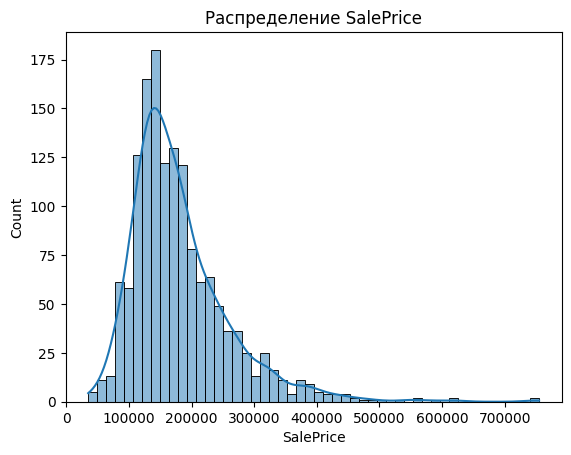

In [ ]:
# Первичный осмотр
display(df.describe(include='all').T)

# Количество пропущенных значений
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(f"Признаки с пропущенными значениями:\n{missing}")

# Распределение целевой переменной
sns.histplot(df[TARGET], kde=True, bins=50)
plt.title("Распределение SalePrice")
plt.show()


In [ ]:
# Убираем строки с пропусками в таргете
df = df.dropna(subset=[TARGET])

# Разделение на X и y
X = df.drop(columns=[TARGET])
y = df[TARGET]

# Выделим числовые и категориальные признаки
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Кол-во числовых признаков: {len(numeric_cols)}")
print(f"Кол-во категориальных признаков: {len(categorical_cols)}")


Кол-во числовых признаков: 37
Кол-во категориальных признаков: 43


Дальше мы пошагово решим серию задач, создавая автоматизированный инструмент для подбора моделей под конкретный кейс.

> **Важно.** В лонгриде этой недели уже есть примеры работы с `Optuna`, `Pipeline` и кросс-валидацией.

## Задача 6

**Задача:** собрать гибкий, настраиваемый и пригодный для тюнинга в `Optuna` `sklearn-pipeline` на основе [ColumnTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html).

**Алгоритм решения**

1. Напиши функцию `build_pipeline`, собирающую модульный [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html), который можно будет легко настроить. Выше мы уже разделили признаки на числовые и категориальные.
2. Через Pipeline cоздай их препроцессинг:
 * для числовых признаков: [SimpleImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html) + [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html);
 * для категориальных признаков: `SimpleImputer(strategy='most_frequent')` + [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) (`handle_unknown='ignore'`, `sparse_output = False`).
3. Собери `ColumnTransformer` с этим препроцессингом.
4. Создай финальный Pipeline: ColumnTransformer + [LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html).

**Чек-лист для самопроверки**
1. Готовый пайплайн пригоден для подачи в `cross_val_score`.
2. Нет утечек (Data Leakage).
3. При вызове функции модель и параметры трансформеров легко заменяются.


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression

def build_pipeline(strategy_num="median",
                   strategy_cat="most_frequent",
                   model=None):
    if model is None:
        model = LinearRegression()

    numeric_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy=strategy_num)),
        ("scaler", StandardScaler())
    ])

    categorical_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy=strategy_cat)),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ])

    preprocessor = ColumnTransformer([
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols)
    ])

    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

In [ ]:
from sklearn.model_selection import cross_val_score, KFold

# Передадим Pipeline в cross_val_score — будет ли это работать? Если всё правильно, то ошибки не будет

pipe = build_pipeline(strategy_num="median", model=LinearRegression())

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(pipe, X, y, cv=cv, scoring="r2")
print(f"R² (CV): {scores.mean():.4f} ± {scores.std():.4f}")

R² (CV): 0.7787 ± 0.1571


In [ ]:
from sklearn.linear_model import Ridge

# Протестируем функцию — появится ли ошибка? Если всё правильно, то ошибки не будет
build_pipeline(strategy_num="mean", model=None)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Id', 'MSSubClass',
                                                   'LotFrontage', 'LotArea',
                                                   'OverallQual', 'OverallCond',
                                                   'YearBuilt', 'YearRemodAdd',
                                                   'MasVnrArea', 'BsmtFinSF1',
                                                   'BsmtFinSF2', 'BsmtUnfSF',
                                                   'TotalBsmtSF', '1stFlrSF',
                                                   '2ndFlrSF', 'LowQualFinSF',
                                                   'GrLi...
                                                   'LandContour', 'Utilities',
                                                   'LotConfig', 'LandSlope',
                                                   'Neighborhood', 'Condition1',
                                                   'Condition2', 'BldgType',
                                                   'HouseStyle', 'RoofStyle',
                                                   'RoofMatl', 'Exterior1st',
                                                   'Exterior2nd', 'MasVnrType',
                                                   'ExterQual', 'ExterCond',
                                                   'Foundation', 'BsmtQual',
                                                   'BsmtCond', 'BsmtExposure',
                                                   'BsmtFinType1',
                                                   'BsmtFinType2', 'Heating',
                                                   'HeatingQC', 'CentralAir',
                                                   'Electrical', ...])])),
                ('model', LinearRegression())])

In [ ]:
# А так? Если всё правильно, то ошибки не будет

build_pipeline(model=Ridge(alpha=10))

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Id', 'MSSubClass',
                                                   'LotFrontage', 'LotArea',
                                                   'OverallQual', 'OverallCond',
                                                   'YearBuilt', 'YearRemodAdd',
                                                   'MasVnrArea', 'BsmtFinSF1',
                                                   'BsmtFinSF2', 'BsmtUnfSF',
                                                   'TotalBsmtSF', '1stFlrSF',
                                                   '2ndFlrSF', 'Lo...
                                                   'LandContour', 'Utilities',
                                                   'LotConfig', 'LandSlope',
                                                   'Neighborhood', 'Condition1',
                                                   'Condition2', 'BldgType',
                                                   'HouseStyle', 'RoofStyle',
                                                   'RoofMatl', 'Exterior1st',
                                                   'Exterior2nd', 'MasVnrType',
                                                   'ExterQual', 'ExterCond',
                                                   'Foundation', 'BsmtQual',
                                                   'BsmtCond', 'BsmtExposure',
                                                   'BsmtFinType1',
                                                   'BsmtFinType2', 'Heating',
                                                   'HeatingQC', 'CentralAir',
                                                   'Electrical', ...])])),
                ('model', Ridge(alpha=10))])

### Ответы на вопросы, которые могли возникнуть

1. Почему мы применяем иммутацию до масштабирования?

 `StandardScaler` поддерживает NaN: игнорирует пропуски при обучении и сохраняет их при преобразовании. Здесь `SimpleImputer` заполняет пропуски, чтобы последующая линейная модель могла обработать данные.


2. Зачем мы используем OneHot?

 Чтобы предобработать категориальные признаки.

3. Зачем в OneHot передавать параметр `handle_unknown='ignore'`?
  
  В обратном случае валидация упадёт на новых категориях.

4. Зачем мы обернули всё в функцию `build_pipeline`?

  Чтобы затем вызывать `build_pipeline` в `objective(trial)` от `Optuna`:
  
   `objective(trial)` для `Optuna` — `model = build_pipeline(strategy_num="median", strategy_cat="most_frequent", model=Ridge(alpha=1.0))`.

## Задача 7

**Задача**
* Необходимо интегрировать `build_pipeline` в Optuna-оптимизируемый `objective`.
* Так мы сможем настраивать сразу несколько гиперпараметров: как у препроцессоров, так и у модели.

**Алгоритм решения:**
напиши функцию `objective(trial)` для `Optuna`. Эта функция:
1. Перебирает гиперпараметры:
 * strategy_num: `"mean" / "median"`;
 * strategy_cat: `"most_frequent" / "constant"`;
 * model: `Ridge` с параметром `alpha ∈ [1e-3, 1e3]` (Log-uniform).
2. Собирает пайплайн через функцию `build_pipeline(...)`.
3. Вычисляет `cross_val_score(..., scoring='neg_root_mean_squared_error')`.
4. Возвращает усреднённую ошибку (по модулю).

**Чек-лист для самопроверки**
1. Используется `KFold(n_splits=5, shuffle=True, random_state=42)`.
2. Оптимизация проводится по RMSE (чем меньше, тем лучше).
3. Показан лучший результат (`study.best_params`, `study.best_value`).
4. Нет утечек (Data Leakage).
5. Результат интерпретируется следующим образом: какие параметры выбраны и какому значению метрики они соответствуют.


In [ ]:
!pip install optuna
import optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 23.8 MB/s eta 0:00:00


In [ ]:
def objective(trial):
    strategy_num = trial.suggest_categorical("strategy_num", ["mean", "median"])
    strategy_cat = trial.suggest_categorical("strategy_cat", ["most_frequent", "constant"])
    alpha = trial.suggest_float("alpha", 1e-3, 1e3, log=True)

    model = Ridge(alpha=alpha)

    pipe = build_pipeline(strategy_num=strategy_num,
                          strategy_cat=strategy_cat,
                          model=model)

    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    scores = cross_val_score(pipe, X, y, cv=cv, scoring="neg_root_mean_squared_error")

    return -scores.mean()

In [ ]:
# Проверим, работает ли objective и какие параметры удалось отобрать

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=30)

print("Best score (RMSE):", study.best_value)
print("Best parameters:")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")

[I 2026-09-19 08:08:40,936] A new study created in memory with name: no-name-b732b19a-7a1a-4f47-aa69-76d4748c488d
[I 2026-09-19 08:08:41,607] Trial 0 finished with value: 33609.167597930646 and parameters: {'strategy_num': 'median', 'strategy_cat': 'constant', 'alpha': 141.97368126815437}. Best is trial 0 with value: 33609.167597930646.
[I 2026-09-19 08:08:42,260] Trial 1 finished with value: 33978.49238203503 and parameters: {'strategy_num': 'median', 'strategy_cat': 'most_frequent', 'alpha': 0.38369896139225784}. Best is trial 0 with value: 33609.167597930646.
[I 2026-09-19 08:08:42,975] Trial 2 finished with value: 33258.43581374105 and parameters: {'strategy_num': 'mean', 'strategy_cat': 'constant', 'alpha': 3.5801568128756225}. Best is trial 2 with value: 33258.43581374105.
[I 2026-09-19 08:08:43,713] Trial 3 finished with value: 33196.778543742475 and parameters: {'strategy_num': 'median', 'strategy_cat': 'constant', 'alpha': 5.069865581298895}. Best is trial 3 with value: 33196.

Best score (RMSE): 32998.50644289763
Best parameters:
  strategy_num: median
  strategy_cat: most_frequent
  alpha: 21.597607201826783


### Ответы на вопросы, которые могли возникнуть

1. Почему мы используем такой алгоритм действий?

  - Гиперпараметры трансформеров влияют на результат: нам нужно попробовать их подобрать.
  - Оптимизируем RMSE, а не R², так как она ближе к бизнес-интерпретации работы решения.
2. Почему используем `log-uniform` для `alpha`?

  Параметр `alpha` чувствителен к порядку, с ним удобнее работать через логарифм.

3. Почему `cross_val_score` находится внутри `objective()`?

  Чтобы получить более стабильную и независимую от случайности оценку.










## Теперь ты умеешь

* Применять на практике разные типы кросс-валидации.
* Строить пайплайны с `ColumnTransformer` для обработки числовых и категориальных признаков.
* Избегать Data Leakage при работе с подбором гиперпараметров.
* Подбирать гиперпараметры с помощью `Optuna` и  `OptunaSearchCV`.


# Обратная связь по семинару для очной магистратуры

Пройди короткий опрос по [ссылке](https://polls.tbank.ru/s/cmt6wf8lr000s0ds6c5a0gedj) или QR-коду ниже.

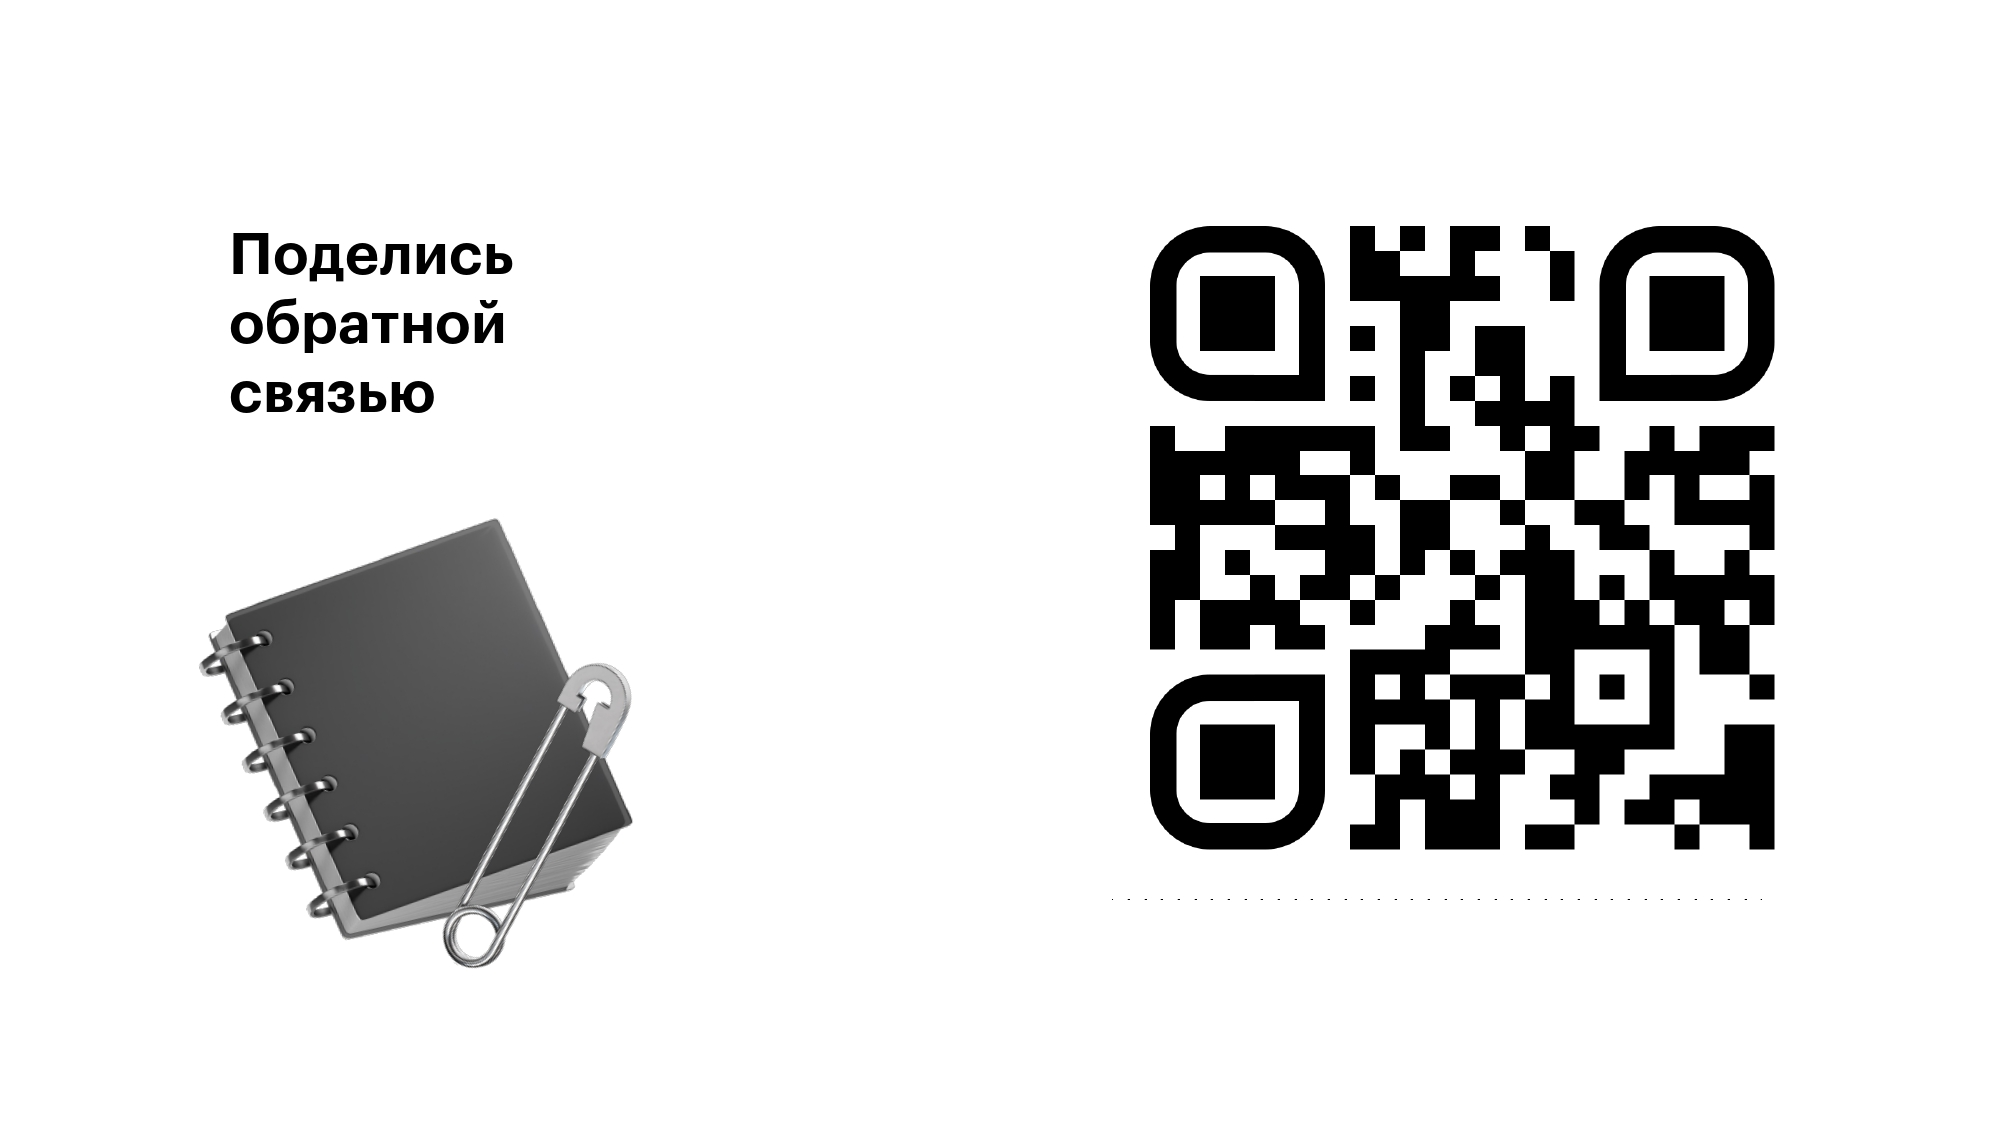

# Обратная связь по семинару для онлайн-магистратуры

Пройди короткий опрос по [ссылке](https://polls.tbank.ru/s/cms63133e00440dribvbmail8) или QR-коду ниже.

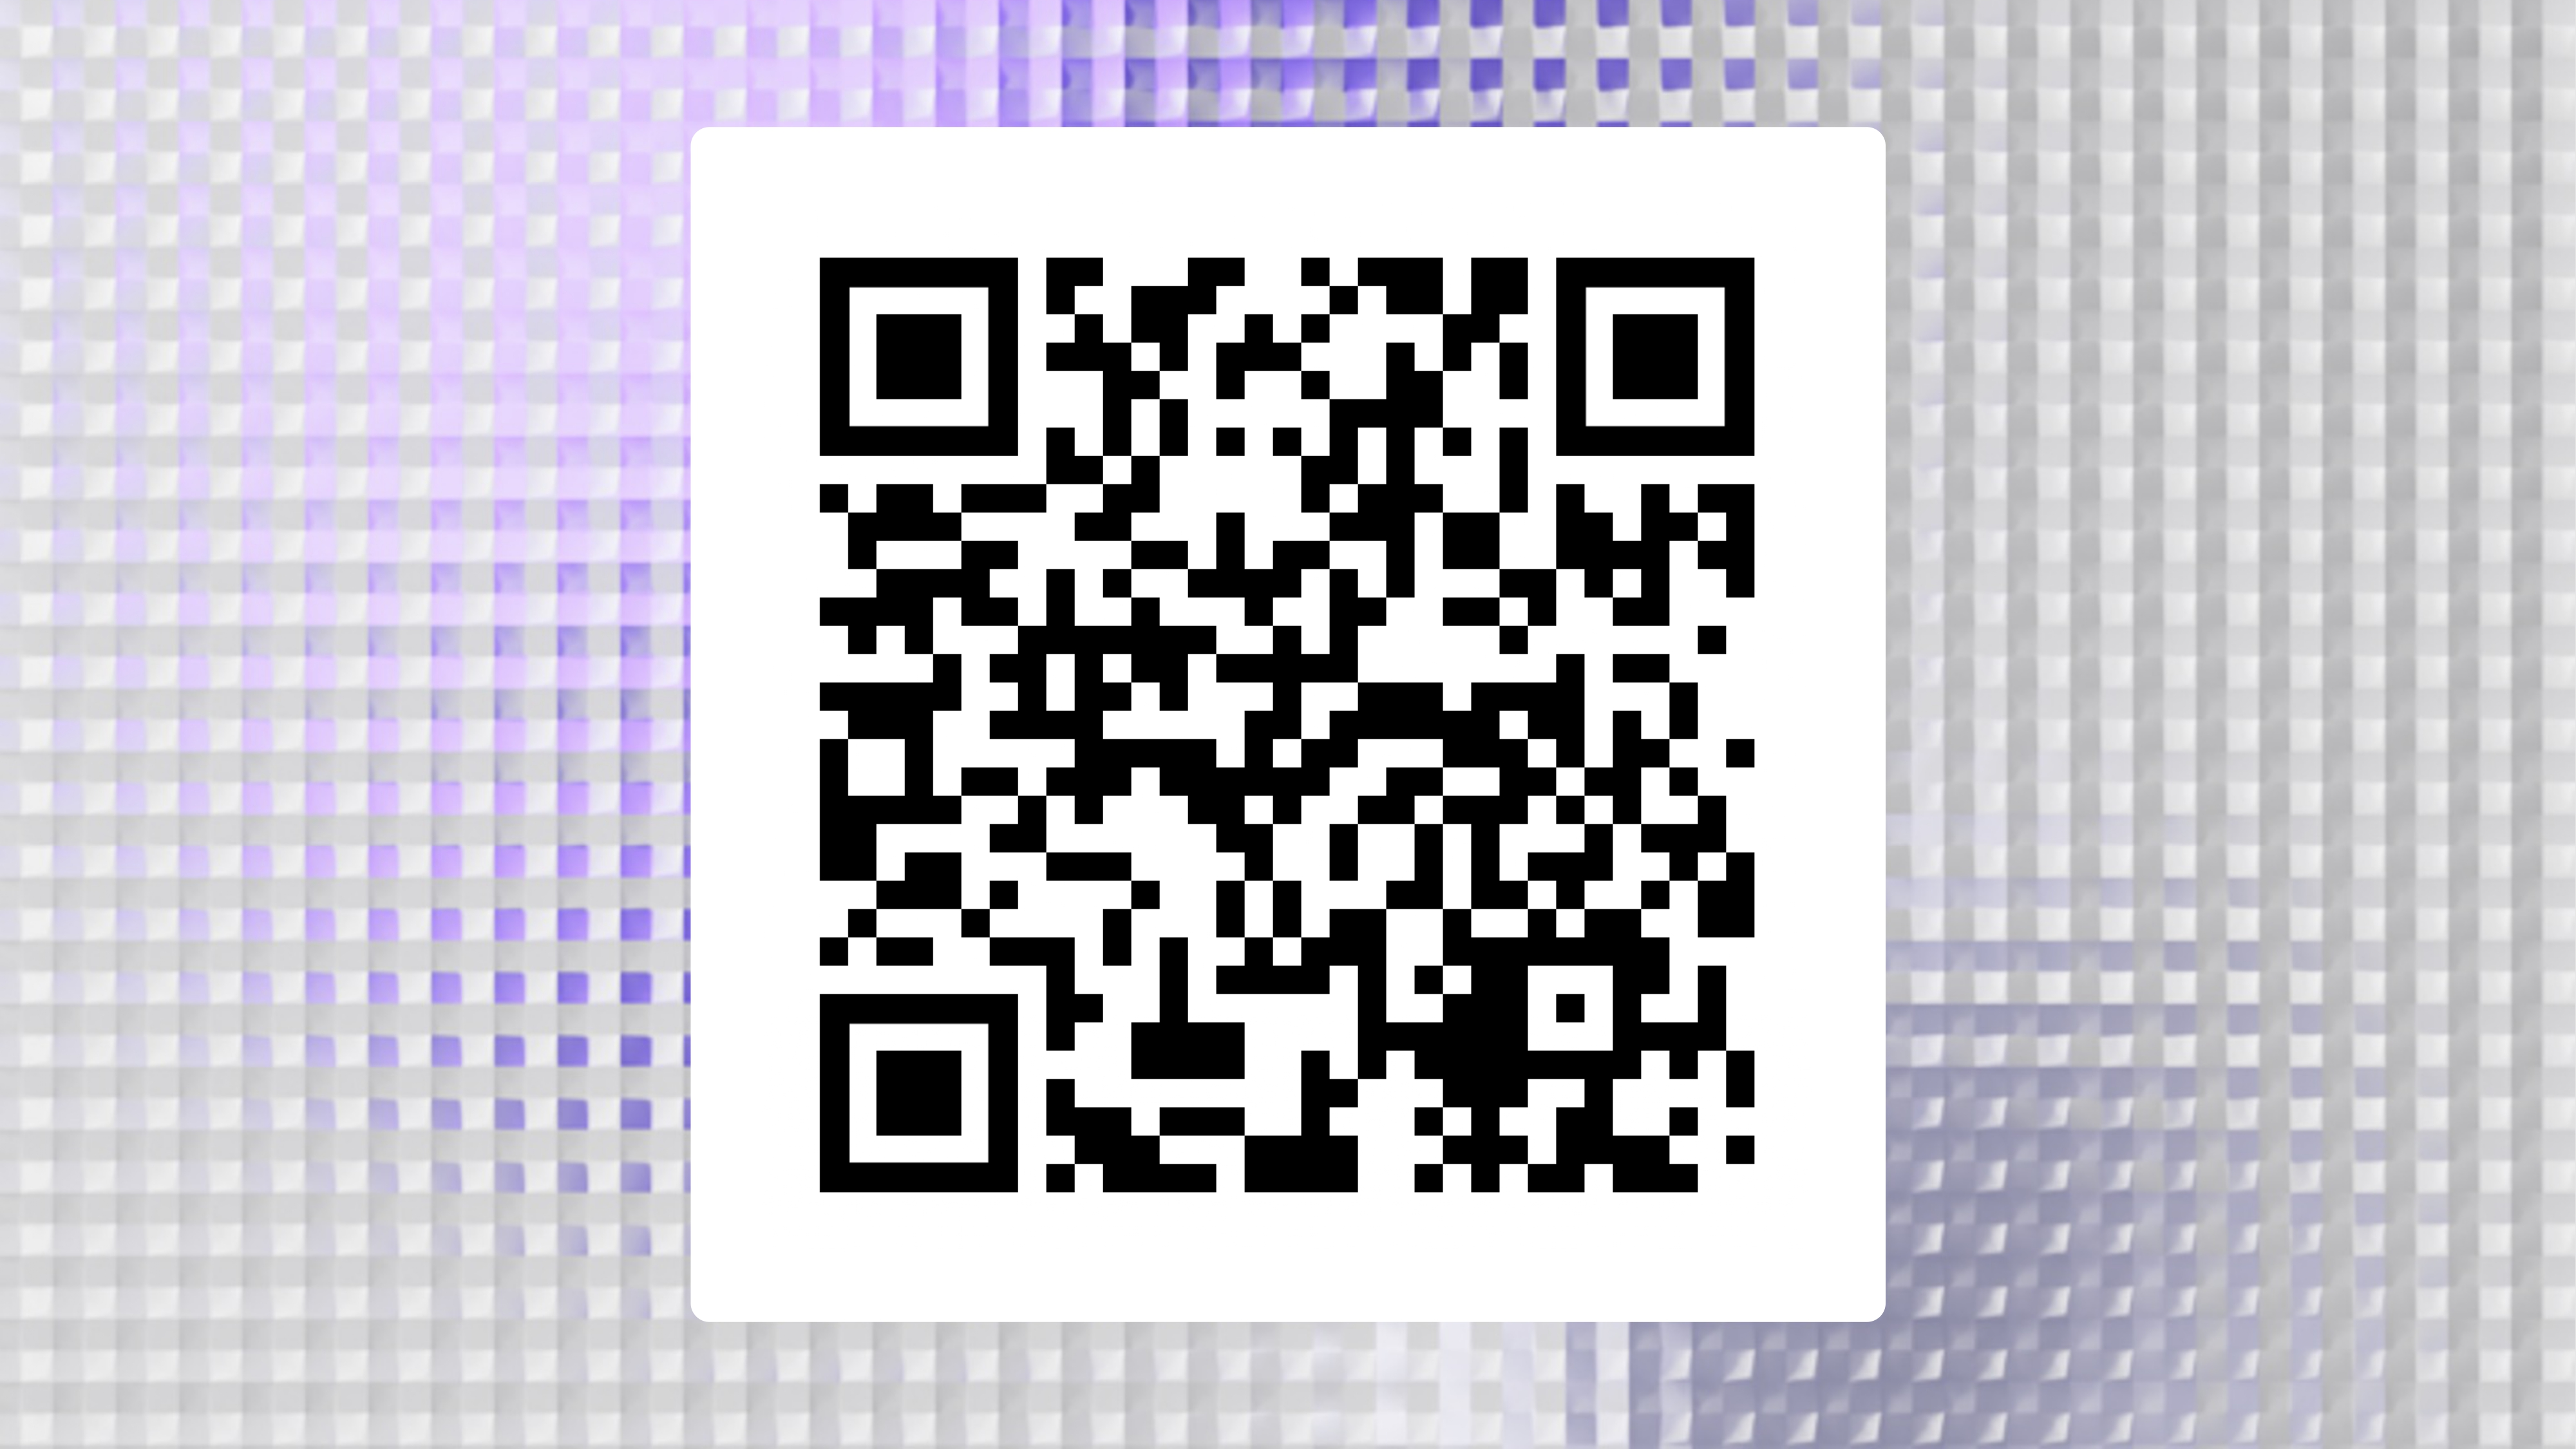